
# Análisis Multivariado de Varianza
## Ejemplo: Comparación de Métodos de Enseñanza
## Actividad MANOVA
### Dr. Hugo García Tecocoatzi

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

In [2]:
# Generar datos sintéticos para el ejemplo
np.random.seed(42)

# Parámetros
n_por_grupo = 30
grupos = ['A', 'B', 'C']

# Método A: Enseñanza tradicional
# Matemáticas: media 75, Lectura: media 70
mat_A = np.random.normal(75, 8, n_por_grupo)
lec_A = np.random.normal(70, 8, n_por_grupo)

# Método B: Enseñanza activa
# Matemáticas: media 82, Lectura: media 78
mat_B = np.random.normal(82, 8, n_por_grupo)
lec_B = np.random.normal(78, 8, n_por_grupo)

# Método C: Enseñanza híbrida
# Matemáticas: media 78, Lectura: media 75
mat_C = np.random.normal(78, 8, n_por_grupo)
lec_C = np.random.normal(75, 8, n_por_grupo)

# Crear DataFrame
df = pd.DataFrame({
    'Metodo': ['A']*n_por_grupo + ['B']*n_por_grupo + ['C']*n_por_grupo,
    'Matematicas': np.concatenate([mat_A, mat_B, mat_C]),
    'Lectura': np.concatenate([lec_A, lec_B, lec_C])
})

# Asegurar que las calificaciones estén en rango [0, 100]
df['Matematicas'] = np.clip(df['Matematicas'], 0, 100)
df['Lectura'] = np.clip(df['Lectura'], 0, 100)

print("Datos generados exitosamente")
print(f"Forma del dataset: {df.shape}")
print(f"Grupos: {df['Metodo'].unique()}")
df.head(10)

Datos generados exitosamente
Forma del dataset: (90, 3)
Grupos: <ArrowStringArray>
['A', 'B', 'C']
Length: 3, dtype: str


,Metodo,Matematicas,Lectura
0,A,78.973713,65.186347
1,A,73.893886,84.818225
2,A,80.181508,69.892022
3,A,87.184239,61.538313
4,A,73.126773,76.580359
5,A,73.126904,60.233251
6,A,87.633703,71.670909
7,A,81.139478,54.322639
8,A,71.244205,59.374512
9,A,79.340480,71.574890


In [3]:
#  Estadísticas descriptivas por grupo
print("ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: \n")

estadisticas = df.groupby('Metodo').agg({
    'Matematicas': ['mean', 'std', 'min', 'max'],
    'Lectura': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: 

       Matematicas                     Lectura                    
              mean   std    min    max    mean   std    min    max
Metodo                                                            
A            73.49  7.20  59.69  87.63   69.03  7.45  54.32  84.82
B            82.10  7.94  61.04  94.52   77.84  7.27  62.65  97.71
C            77.24  8.19  65.14  95.52   77.23  7.58  65.47  96.76


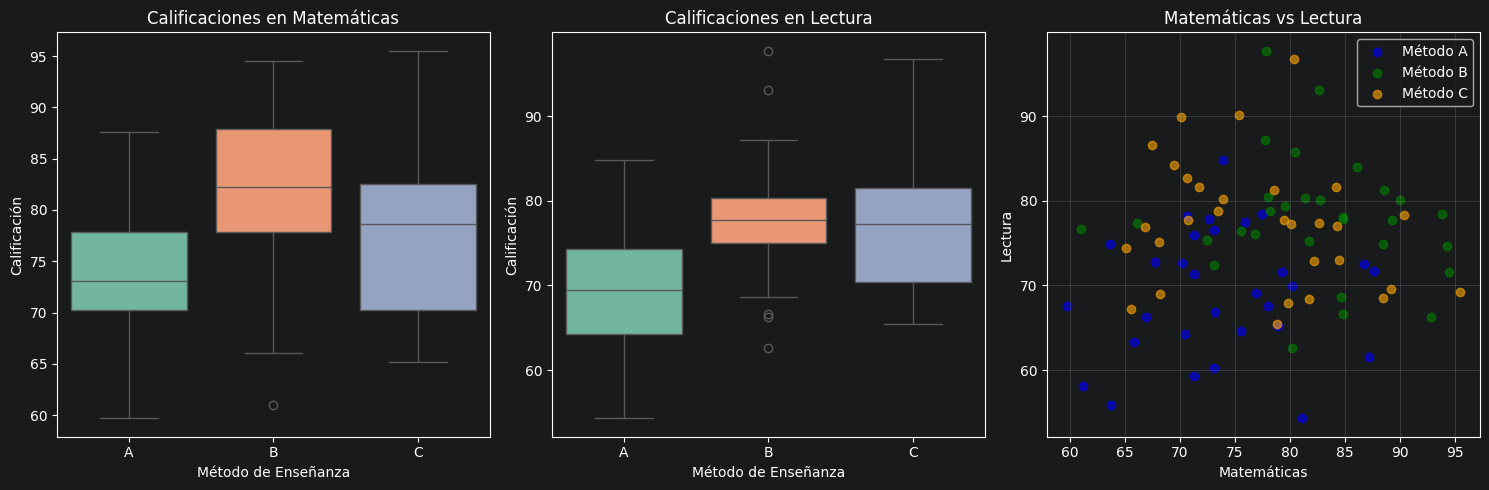

In [4]:
# Visualización 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot Matemáticas
sns.boxplot(x='Metodo', y='Matematicas', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Calificaciones en Matemáticas')
axes[0].set_xlabel('Método de Enseñanza')
axes[0].set_ylabel('Calificación')

# Boxplot Lectura
sns.boxplot(x='Metodo', y='Lectura', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Calificaciones en Lectura')
axes[1].set_xlabel('Método de Enseñanza')
axes[1].set_ylabel('Calificación')

# Scatter plot Matemáticas vs Lectura
colors = {'A': 'blue', 'B': 'green', 'C': 'orange'}
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo]
    axes[2].scatter(subset['Matematicas'], subset['Lectura'], 
                    alpha=0.6, label=f'Método {metodo}', color=colors[metodo])
axes[2].set_xlabel('Matemáticas')
axes[2].set_ylabel('Lectura')
axes[2].set_title('Matemáticas vs Lectura')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

             Matematicas  Lectura
Matematicas       1.0000   0.0886
Lectura           0.0886   1.0000


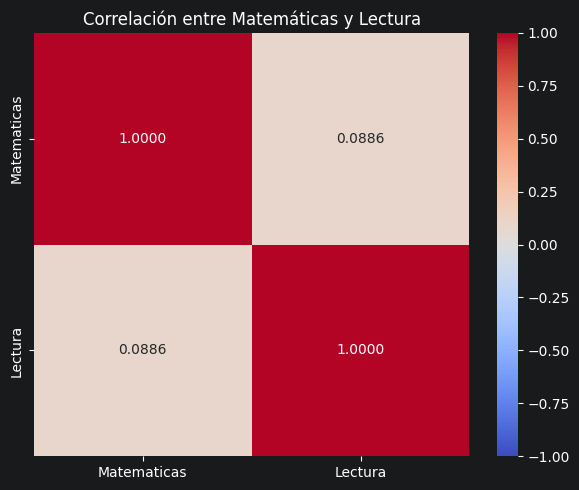

In [5]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Matematicas', 'Lectura']].corr().round(4))

# Visualización
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Matematicas', 'Lectura']].corr(), 
            annot=True, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Matemáticas y Lectura')
plt.tight_layout()
plt.show()

In [6]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Matematicas + Lectura ~ Metodo', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value  Num DF  Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda  0.0146 2.0000 86.0000 2907.3547 0.0000
         Pillai's trace  0.9854 2.0000 86.0000 2907.3547 0.0000
 Hotelling-Lawley trace 67.6129 2.0000 86.0000 2907.3547 0.0000
    Roy's greatest root 67.6129 2.0000 86.0000 2907.3547 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
           Metodo         Value  Num DF  Den DF  F Value Pr > F
---------------------------------------------------------------
            Wilks' lambda 0.6317 4.0000 172.0000 11.1040 0.0000
           Pillai's trace 0.3790 4.0000 174.0000 1

In [7]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Metodo']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                           Value Num DF      Den DF    F Value Pr > F
Wilks' lambda           0.631651      4       172.0  11.104044    0.0
Pillai's trace          0.379027    4.0       174.0  10.171469    0.0
Hotelling-Lawley trace  0.566246      4  102.169014  12.128592    0.0
Roy's greatest root     0.534625      2          87  23.256178    0.0


In [8]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'p-value' in resultados_mv.columns:
        p_valor = resultados_mv.loc[estadistico, 'Pr > F']
        valor = resultados_mv.loc[estadistico, 'Value']
        
        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Si todos los estadísticos son significativos (p < 0.05),")
print("existe evidencia de que los métodos de enseñanza difieren")
print("en el patrón conjunto de Matemáticas y Lectura.")

=== INTERPRETACIÓN DE RESULTADOS ===


 Conclusión:
Si todos los estadísticos son significativos (p < 0.05),
existe evidencia de que los métodos de enseñanza difieren
en el patrón conjunto de Matemáticas y Lectura.


In [9]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

# ANOVA para Matemáticas
print("ANOVA para Matemáticas:")
modelo_mat = ols('Matematicas ~ Metodo', data=df).fit()
anova_mat = sm.stats.anova_lm(modelo_mat, typ=2)
print(anova_mat.round(4))

# ANOVA para Lectura
print("\n ANOVA para Lectura:")
modelo_lec = ols('Lectura ~ Metodo', data=df).fit()
anova_lec = sm.stats.anova_lm(modelo_lec, typ=2)
print(anova_lec.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 2  # 2 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_mat = anova_mat.loc['Metodo', 'PR(>F)']
p_lec = anova_lec.loc['Metodo', 'PR(>F)']

print(f"\n   Matemáticas: p = {p_mat:.4f} → {'Significativo' if p_mat < alpha_bonferroni else 'No significativo'}")
print(f"   Lectura: p = {p_lec:.4f} → {'Significativo' if p_lec < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Matemáticas:
             sum_sq    df      F  PR(>F)
Metodo    1117.7714   2.0  9.215  0.0002
Residual  5276.5085  87.0    NaN     NaN

 ANOVA para Lectura:
             sum_sq    df        F  PR(>F)
Metodo    1451.7091   2.0  13.1348     0.0
Residual  4807.8024  87.0      NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.025

   Matemáticas: p = 0.0002 → Significativo
   Lectura: p = 0.0000 → Significativo


In [10]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Matemáticas
print("Tukey HSD para Matemáticas:")
tukey_mat = pairwise_tukeyhsd(df['Matematicas'], df['Metodo'], alpha=0.05)
print(tukey_mat)

print("\n Tukey HSD para Lectura:")
tukey_lec = pairwise_tukeyhsd(df['Lectura'], df['Metodo'], alpha=0.05)
print(tukey_lec)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Matemáticas:
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   8.6083 0.0001  3.8136 13.403   True
     A      C   3.7455 0.1558 -1.0492 8.5402  False
     B      C  -4.8627 0.0461 -9.6574 -0.068   True
---------------------------------------------------

 Tukey HSD para Lectura:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B   8.8073    0.0  4.2305 13.3841   True
     A      C   8.1996 0.0001  3.6228 12.7764   True
     B      C  -0.6077 0.9463 -5.1845  3.9691  False
----------------------------------------------------


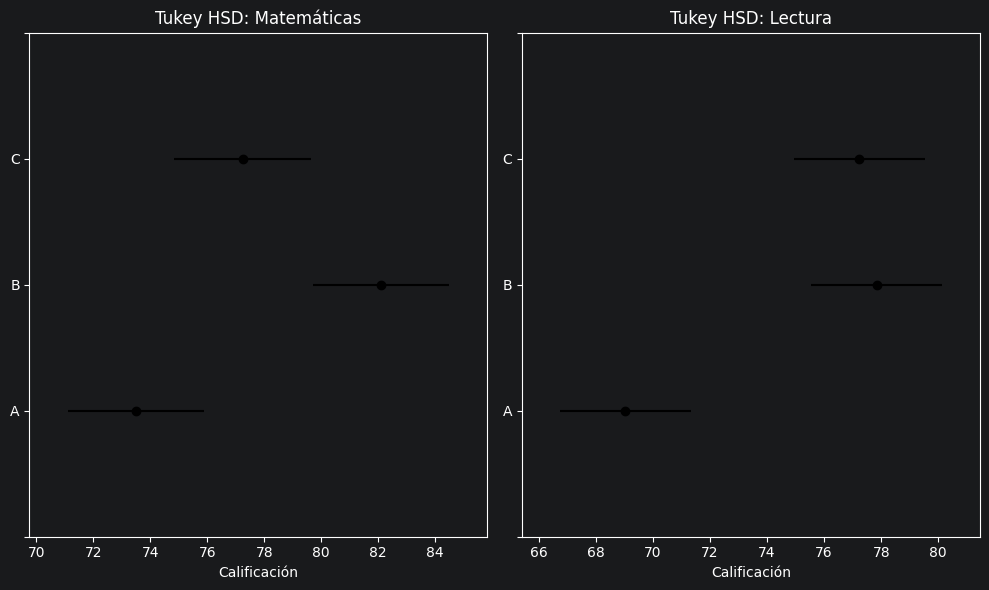

In [11]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tukey Matemáticas
tukey_mat.plot_simultaneous(ax=axes[0])
axes[0].set_title('Tukey HSD: Matemáticas')
axes[0].set_xlabel('Calificación')

# Tukey Lectura
tukey_lec.plot_simultaneous(ax=axes[1])
axes[1].set_title('Tukey HSD: Lectura')
axes[1].set_xlabel('Calificación')

plt.tight_layout()
plt.show()

In [12]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

# Test de Mardia para normalidad multivariada
def mardia_test(data, alpha=0.05):
    """
    Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)
    
    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)
    
    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n
    
    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)
    
    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))
    
    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

# Aplicar test por grupo
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo][['Matematicas', 'Lectura']].values
    print(f"Método {metodo}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")
    
    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Método A:
  Skewness statistic: 1.9333
  Skewness p-value: 0.7480
  Kurtosis statistic: -1.1241
  Kurtosis p-value: 0.2610
  ✅ Normalidad multivariada aceptable

Método B:
  Skewness statistic: 4.0213
  Skewness p-value: 0.4031
  Kurtosis statistic: -0.2271
  Kurtosis p-value: 0.8203
  ✅ Normalidad multivariada aceptable

Método C:
  Skewness statistic: 3.1460
  Skewness p-value: 0.5337
  Kurtosis statistic: -0.9106
  Kurtosis p-value: 0.3625
  ✅ Normalidad multivariada aceptable



In [13]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]
    
    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)
    
    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))
    
    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)
    
    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))
    
    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)
    
    # Estadístico de prueba
    chi2_stat = M * (1 - c)
    
    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2
    
    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)
    
    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 2.3240
  Chi-square: 2.2469
  df: 6.0000
  p-value: 0.8957

✅ No se rechaza H₀: Las matrices de covarianza son homogéneas


# Preguntas de análisis

**1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?**
- Pillai's Trace (con valor de 0.379, F = 10.17, p < 0.001), pues es el más robusto ante violaciones de supuestos y con tamaños de grupo desiguales, en este caso los supuestos se cumplen (n = 30 por grupo con Box's M no significativo), por lo que lambda de Wilks' (0.632, F = 11.10) también es válido y es el que más se reporta, sin embargo, los 4 estadísticos son válidos y nos llevan a la misma conclusión.

**2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?**
- Lectura, pues en los ANOVA univariados tiene un F más alto (13.13 vs 9.22) y una suma de cuadrados entre grupos mayor (1451.7 vs 1117.8), siendo ambas significativas, con un Bonferroni de alpha = 0.025

**3. ¿Qué pares de grupos son significativamente diferentes?**
- Según Tukey HSD:
    - Matemáticas: A–B (diferencia de 8.61, p = 0.0001) y B–C (−4.86, p = 0.046). A–C no es significativo (p = 0.156)
    - Lectura: A–B (8.81, p < 0.001) y A–C (8.20, p = 0.0001). B–C no es significativo (p = 0.946)

**4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?**
- Sí, pues se cumplen todos los supuestos:
    - Normalidad multivariada: se cumple en los tres grupos, todos los p-values de asimetría y curtosis son mayores a 0.05
    - Homogeneidad de covarianzas: χ^2 = 2.25, p = 0.896, así que no se rechaza la igualdad de matrices de covarianza
- Los resultados del MANOVA son confiables y cualquiera de los cuatro estadísticos es válido, solo que la correlación entre Matemáticas y Lectura es muy baja (r = 0.089), sabemos que el MANOVA aprovecha más cuando las variables dependientes están moderadamente correlacionadas, así que aquí aporta poco frente a hacer dos ANOVAs por separado.

**5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?**
- El LDA y el MANOVA se basan en la misma matriz, el MANOVA prueba si los centroides de los grupos difieren, y el LDA encuentra las combinaciones lineales que mejor los separan, la raíz de Roy (0.5346) es el eigenvalor de la primera función discriminante; como la traza de Hotelling-Lawley (0.5662) es la suma de todos los eigenvalores, la primera función discriminante explica alrededor del 94% (0.5346/0.5662) de la separación entre grupos.

# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [15]:
# Celda 3: Cargar el dataset Iris (datos reales)
# El dataset Iris contiene mediciones de 3 especies de flores
iris = load_iris()

# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Especie'] = iris.target_names[iris.target]

# Renombrar columnas para claridad
df.columns = ['Longitud_Sepalo', 'Ancho_Sepalo', 
              'Longitud_Petalo', 'Ancho_Petalo', 'Especie']

print(f"Forma del dataset: {df.shape}")
print(f"Especies: {df['Especie'].unique()}")
print(f"Observaciones por especie:")
print(df['Especie'].value_counts())
df.head(10)

Forma del dataset: (150, 5)
Especies: <ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Observaciones por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [30]:
# Variables dependientes
vars_dep = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']

print("ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: \n")
estadisticas_iris = df.groupby('Especie')[vars_dep].agg(['mean', 'std', 'min', 'max']).round(2)
print(estadisticas_iris.T)

ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: 

Especie               setosa  versicolor  virginica
Longitud_Sepalo mean    5.01        5.94       6.59
                std     0.35        0.52       0.64
                min     4.30        4.90       4.90
                max     5.80        7.00       7.90
Ancho_Sepalo    mean    3.43        2.77       2.97
                std     0.38        0.31       0.32
                min     2.30        2.00       2.20
                max     4.40        3.40       3.80
Longitud_Petalo mean    1.46        4.26       5.55
                std     0.17        0.47       0.55
                min     1.00        3.00       4.50
                max     1.90        5.10       6.90
Ancho_Petalo    mean    0.25        1.33       2.03
                std     0.11        0.20       0.27
                min     0.10        1.00       1.40
                max     0.60        1.80       2.50


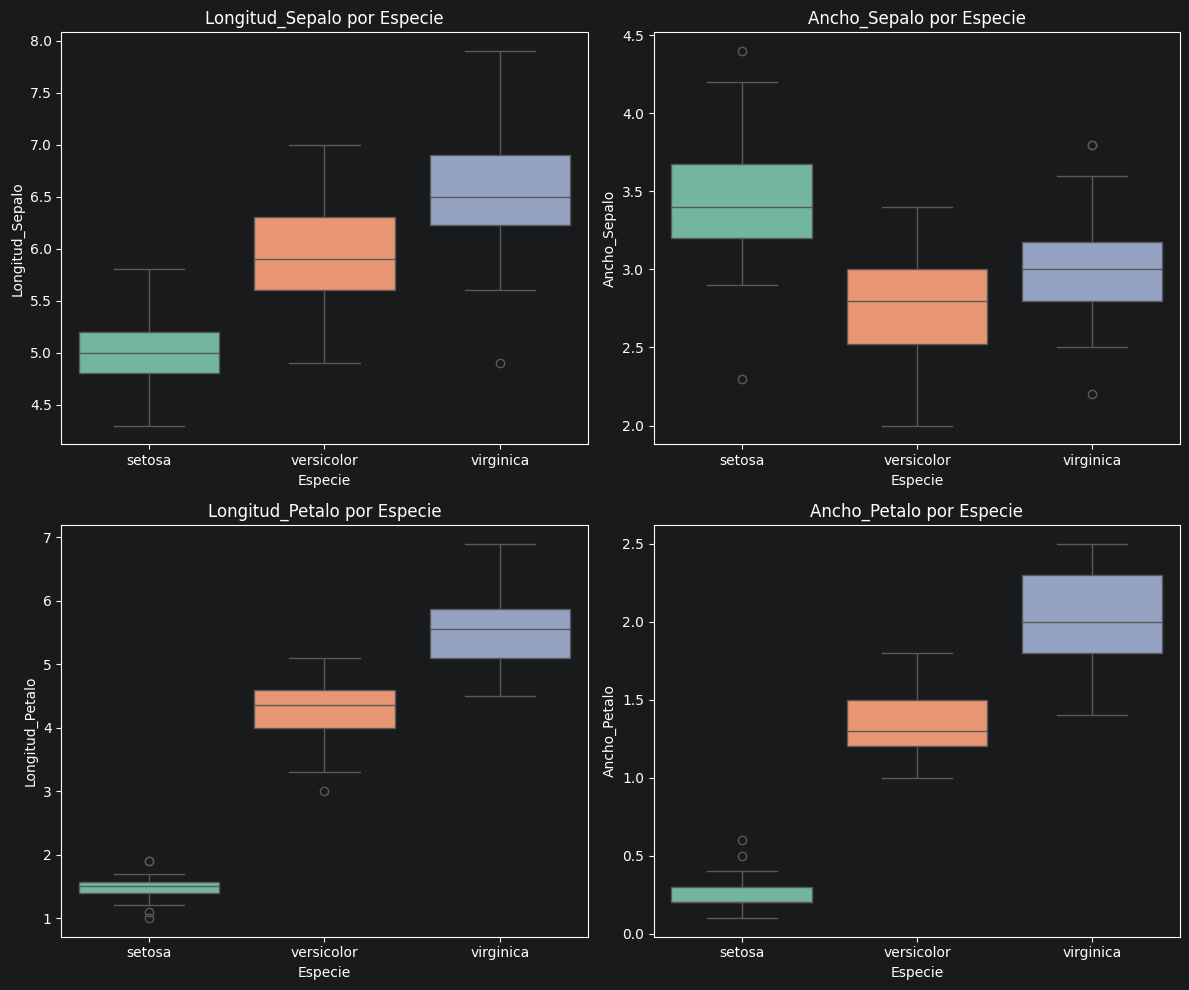

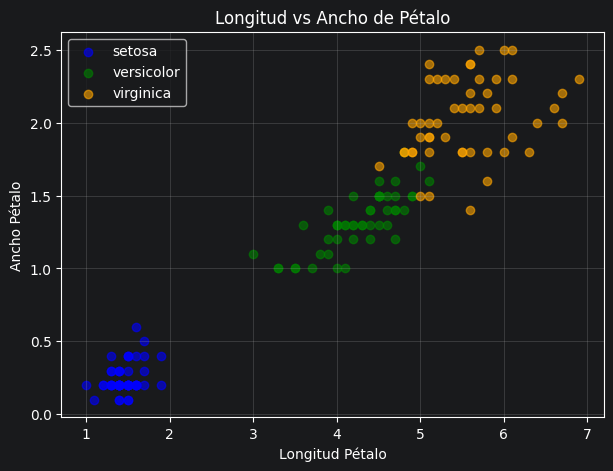

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, var in zip(axes.flatten(), vars_dep):
    sns.boxplot(x='Especie', y=var, data=df, ax=ax, palette='Set2')
    ax.set_title(f'{var} por Especie')
    ax.set_xlabel('Especie')
    ax.set_ylabel(var)
plt.tight_layout()
plt.show()

colors = {'setosa': 'blue', 'versicolor': 'green', 'virginica': 'orange'}
plt.figure(figsize=(7, 5))
for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie]
    plt.scatter(subset['Longitud_Petalo'], subset['Ancho_Petalo'],
                alpha=0.6, label=especie, color=colors[especie])
plt.xlabel('Longitud Pétalo')
plt.ylabel('Ancho Pétalo')
plt.title('Longitud vs Ancho de Pétalo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

MATRIZ DE CORRELACIÓN

                 Longitud_Sepalo  Ancho_Sepalo  Longitud_Petalo  Ancho_Petalo
Longitud_Sepalo           1.0000       -0.1176           0.8718        0.8179
Ancho_Sepalo             -0.1176        1.0000          -0.4284       -0.3661
Longitud_Petalo           0.8718       -0.4284           1.0000        0.9629
Ancho_Petalo              0.8179       -0.3661           0.9629        1.0000


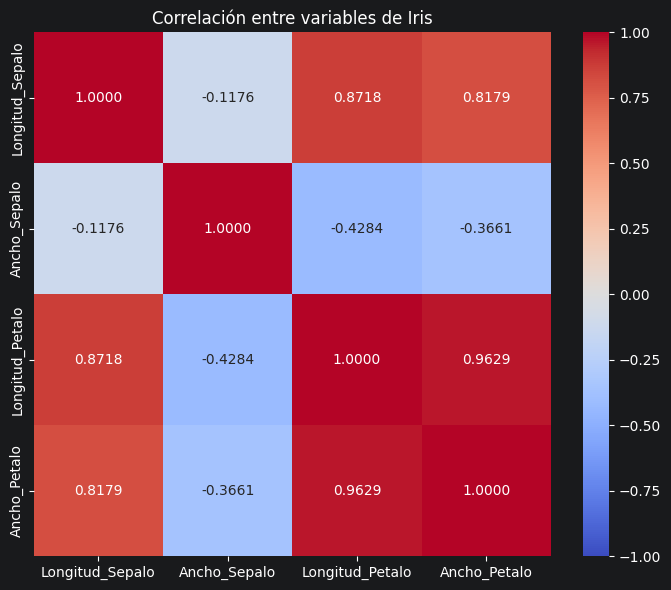

In [32]:
print("MATRIZ DE CORRELACIÓN\n")
print(df[vars_dep].corr().round(4))

plt.figure(figsize=(7, 6))
sns.heatmap(df[vars_dep].corr(), annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre variables de Iris')
plt.tight_layout()
plt.show()

In [35]:
manova_iris = MANOVA.from_formula(
    'Longitud_Sepalo + Ancho_Sepalo + Longitud_Petalo + Ancho_Petalo ~ Especie', data=df)
print(manova_iris.mv_test())

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trace  1.1919 8.0000 290.00

In [44]:
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")
resultados_iris = manova_iris.mv_test().results['Especie']['stat']
print(resultados_iris)

print("\n=== INTERPRETACIÓN ===\n")
for estadistico in resultados_iris.index:
    p_valor = float(resultados_iris.loc[estadistico, 'Pr > F'])
    valor = float(resultados_iris.loc[estadistico, 'Value'])
    if p_valor < 0.05:
        print(f"{estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} -> SIGNIFICATIVO")
    else:
        print(f"{estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} -> NO SIGNIFICATIVO")

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

                            Value Num DF     Den DF      F Value Pr > F
Wilks' lambda            0.023439      8      288.0   199.145344    0.0
Pillai's trace           1.191899    8.0      290.0    53.466489    0.0
Hotelling-Lawley trace   32.47732      8  203.40239   582.197018    0.0
Roy's greatest root     32.191929      4        145  1166.957433    0.0

=== INTERPRETACIÓN ===

Wilks' lambda: Valor = 0.0234, p = 0.0000 -> SIGNIFICATIVO
Pillai's trace: Valor = 1.1919, p = 0.0000 -> SIGNIFICATIVO
Hotelling-Lawley trace: Valor = 32.4773, p = 0.0000 -> SIGNIFICATIVO
Roy's greatest root: Valor = 32.1919, p = 0.0000 -> SIGNIFICATIVO


In [38]:
print("=== ANOVA UNIVARIADO POST-HOC ===\n")
alpha = 0.05
alpha_bonferroni = alpha / len(vars_dep)  # 4 variables → 0.0125
print(f"alpha ajustado (Bonferroni) = {alpha_bonferroni}\n")

for var in vars_dep:
    modelo = ols(f'{var} ~ Especie', data=df).fit()
    tabla = sm.stats.anova_lm(modelo, typ=2)
    print(f"ANOVA para {var}:")
    print(tabla.round(4))
    p = tabla.loc['Especie', 'PR(>F)']
    print(f"-> p = {p:.4e} → {'Significativo' if p < alpha_bonferroni else 'No significativo'}\n")

=== ANOVA UNIVARIADO POST-HOC ===

alpha ajustado (Bonferroni) = 0.0125

ANOVA para Longitud_Sepalo:
           sum_sq     df         F  PR(>F)
Especie   63.2121    2.0  119.2645     0.0
Residual  38.9562  147.0       NaN     NaN
-> p = 1.6697e-31 → Significativo

ANOVA para Ancho_Sepalo:
           sum_sq     df      F  PR(>F)
Especie   11.3449    2.0  49.16     0.0
Residual  16.9620  147.0    NaN     NaN
-> p = 4.4920e-17 → Significativo

ANOVA para Longitud_Petalo:
            sum_sq     df          F  PR(>F)
Especie   437.1028    2.0  1180.1612     0.0
Residual   27.2226  147.0        NaN     NaN
-> p = 2.8568e-91 → Significativo

ANOVA para Ancho_Petalo:
           sum_sq     df         F  PR(>F)
Especie   80.4133    2.0  960.0071     0.0
Residual   6.1566  147.0       NaN     NaN
-> p = 4.1694e-85 → Significativo



COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD)

Tukey HSD para Longitud_Sepalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------

Tukey HSD para Ancho_Sepalo:
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
    setosa versicolor   -0.658    0.0 -0.8189 -0.4971   True
    setosa  virginica   -0.454    0.0 -0.6149 -0.2931   True
versicolor  virginica    0.204 0.0088  0.0431  0.3649   True
------------------------------------------------------------

Tukey HSD para Longitud_Petalo:
   Multiple Comparison of 

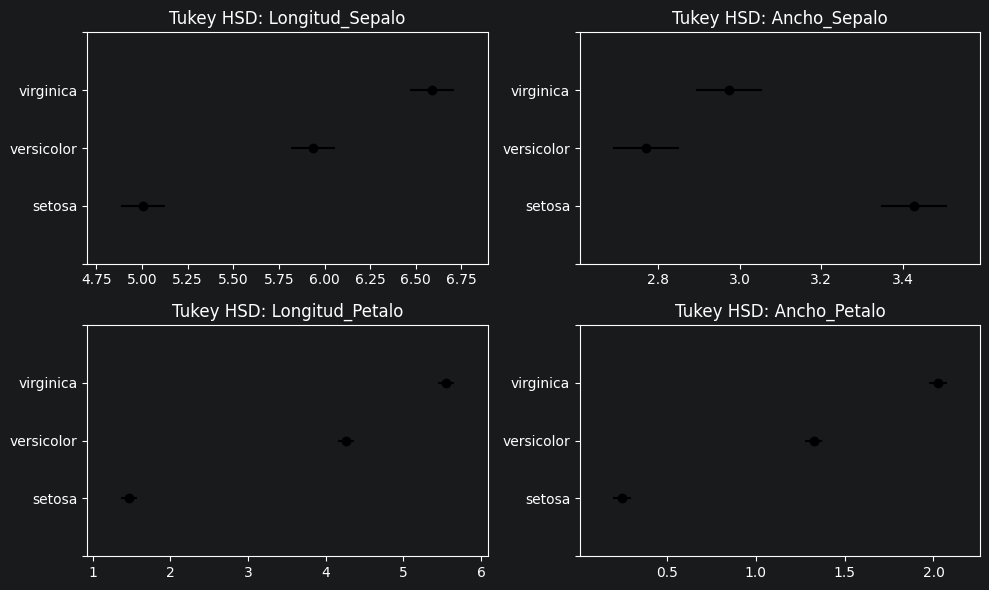

In [39]:
print("COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD)\n")
tukeys = {}
for var in vars_dep:
    tukeys[var] = pairwise_tukeyhsd(df[var], df['Especie'], alpha=0.05)
    print(f"Tukey HSD para {var}:")
    print(tukeys[var])
    print()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, var in zip(axes.flatten(), vars_dep):
    tukeys[var].plot_simultaneous(ax=ax)
    ax.set_title(f'Tukey HSD: {var}')
plt.tight_layout()
plt.show()

In [43]:
print("--- Normalidad Multivariada (Mardia) ---\n")
for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie][vars_dep].values
    print(f"Especie {especie}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")
    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("Normalidad multivariada aceptable")
    else:
        print("Posible violación de normalidad multivariada")
    print()

--- Normalidad Multivariada (Mardia) ---

Especie setosa:
  Skewness statistic: 24.1551
  Skewness p-value: 0.2357
  Kurtosis statistic: 0.7587
  Kurtosis p-value: 0.4480
Normalidad multivariada aceptable

Especie versicolor:
  Skewness statistic: 23.7039
  Skewness p-value: 0.2556
  Kurtosis statistic: -1.0342
  Kurtosis p-value: 0.3010
Normalidad multivariada aceptable

Especie virginica:
  Skewness statistic: 24.7257
  Skewness p-value: 0.2121
  Kurtosis statistic: -0.3384
  Kurtosis p-value: 0.7350
Normalidad multivariada aceptable



In [42]:
print("Homogeneidad de Matrices de Covarianza (Box's M)\n")
resultado_box_iris = box_m_test(df[vars_dep], df['Especie'])
for key, value in resultado_box_iris.items():
    print(f"  {key}: {value:.4f}")

if resultado_box_iris['p-value'] > 0.05:
    print("\nNo se rechaza H_0: Las matrices de covarianza son homogéneas")
else:
    print("\nSe rechaza H_0: Posible violación de homogeneidad de covarianzas")
    print("   -> Considerar usar Pillai's Trace (más robusto)")

Homogeneidad de Matrices de Covarianza (Box's M)

  M statistic: 146.6632
  Chi-square: 140.9430
  df: 20.0000
  p-value: 0.0000

Se rechaza H_0: Posible violación de homogeneidad de covarianzas
   -> Considerar usar Pillai's Trace (más robusto)


In [45]:
# Paso final :D!
# Celda extra para volver el notebook en un .html

!jupyter nbconvert --to html "Actividad6.ipynb"

[NbConvertApp] Converting notebook Actividad6.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 751215 bytes to Actividad6.html
